# NBA Bench Impact Analysis

**Objective:** identify efficient 2023–24 regular-season rotation players who came off the bench more often than they started.

**Success criteria:** one season row per player, explicit sample thresholds, four auditable leaderboards, and reproducible chart exports.

## Source and responsible-use boundary

Statistics come from the [Basketball-Reference 2023–24 per-game player table](https://www.basketball-reference.com/leagues/NBA_2024_per_game.html). The raw table is not included in this repository. Follow `data/README.md` to obtain it manually and review the current Sports Reference terms.

## Analysis plan

1. Load and validate the regular-season table.
2. Resolve traded-player team stints using the aggregate `2TM`/`3TM` row.
3. Define bench-majority rotation players as `G >= 40` and `G - GS > GS`.
4. Apply attempt thresholds before ranking shooting percentages.
5. Export compact tables and four recruiter-facing figures.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.nba_analysis import (
    build_leaderboards,
    leaderboard_exports,
    load_player_stats,
    plot_leaderboard,
    prepare_bench_rotation,
)

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

In [2]:
default_path = ROOT / 'data' / 'raw' / 'nba_2023_24_per_game.csv'
data_path = Path(os.environ.get('NBA_DATA_PATH', default_path))
figure_dir = ROOT / 'assets' / 'figures'
result_dir = ROOT / 'results'
figure_dir.mkdir(parents=True, exist_ok=True)
result_dir.mkdir(parents=True, exist_ok=True)

players = load_player_stats(data_path)
print(f'Loaded {len(players):,} regular-season rows from {data_path.name}.')

Loaded 735 regular-season rows from Book1updated.xlsx.


## Cohort construction and quality checks

In [3]:
cohort, quality = prepare_bench_rotation(players, min_games=40)
pd.Series(quality, name='value').to_frame()

,value
source_rows,735
unique_player_rows,572
multi_team_rows_removed,163
qualified_bench_players,185
minimum_games,40


The multi-team reduction is important: traded players otherwise appear once for each team stint plus once for their full-season aggregate. The cohort uses only the aggregate row, preventing duplicate rankings.

In [4]:
boards = build_leaderboards(cohort, top_n=10)
exports = leaderboard_exports(boards)
for name, table in exports.items():
    table.to_csv(result_dir / f'{name}_leaders.csv', index=False)

summary = pd.DataFrame({
    'category': ['Three-point percentage', 'Two-point percentage', 'Free-throw percentage', 'Rebounds'],
    'leader': [
        boards['three_point'].iloc[0]['Player'],
        boards['two_point'].iloc[0]['Player'],
        boards['free_throw'].iloc[0]['Player'],
        boards['rebounding'].iloc[0]['Player'],
    ],
    'value': [
        boards['three_point'].iloc[0]['3P%'],
        boards['two_point'].iloc[0]['2P%'],
        boards['free_throw'].iloc[0]['FT%'],
        boards['rebounding'].iloc[0]['TRB'],
    ],
})
summary

,category,leader,value
0,Three-point percentage,Norman Powell,0.435
1,Two-point percentage,Walker Kessler,0.680
2,Free-throw percentage,Bogdan Bogdanović,0.921
3,Rebounds,Andre Drummond,9.000


## Three-point shooting — at least 4.0 attempts per game

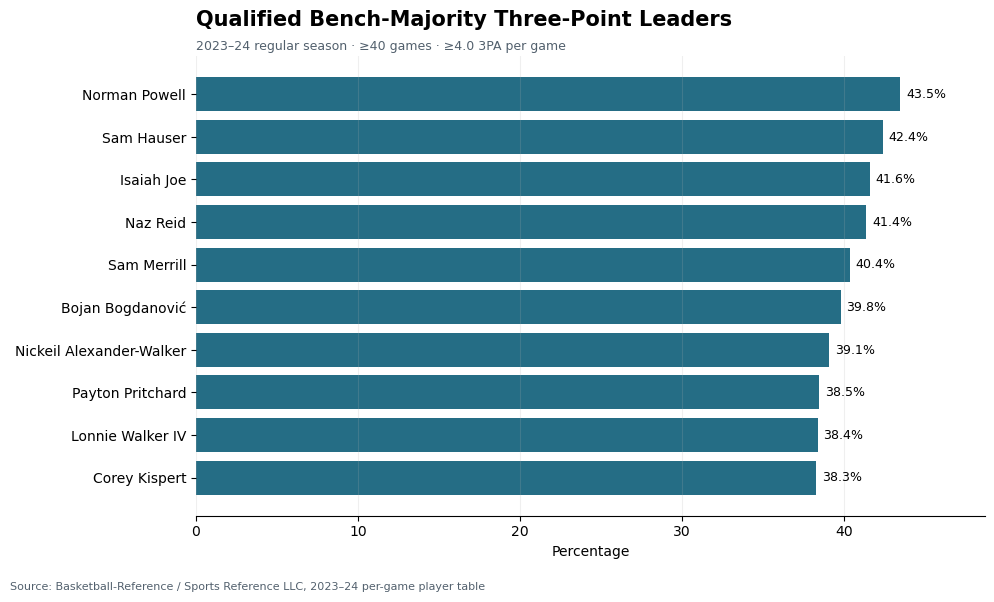

In [5]:
fig = plot_leaderboard(
    boards['three_point'], value_column='3P%',
    title='Qualified Bench-Majority Three-Point Leaders',
    subtitle='2023–24 regular season · ≥40 games · ≥4.0 3PA per game',
    output_path=figure_dir / 'three_point_leaders.png', percentage=True,
)
plt.show()

## Two-point shooting — at least 5.0 attempts per game

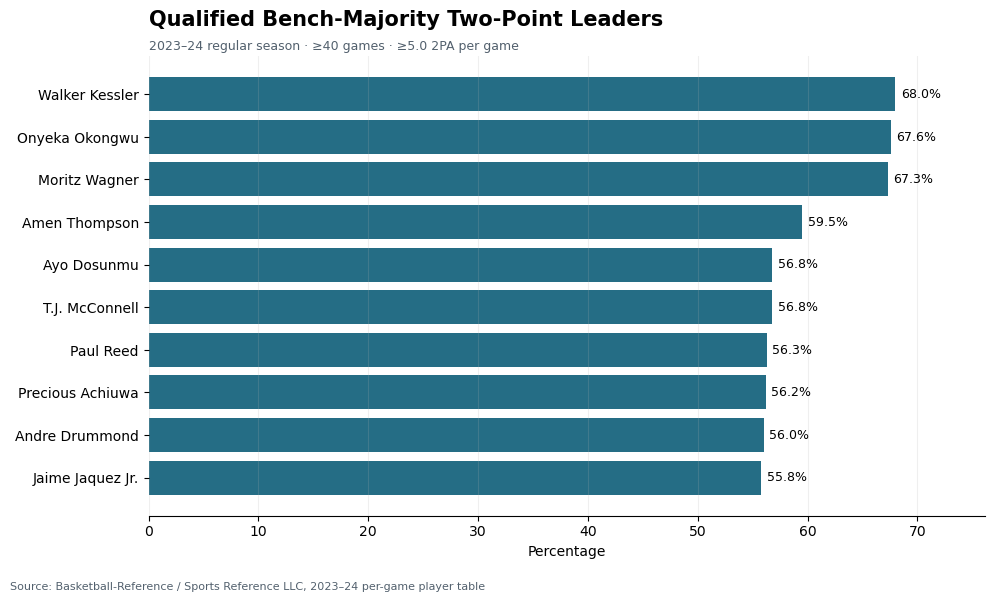

In [6]:
fig = plot_leaderboard(
    boards['two_point'], value_column='2P%',
    title='Qualified Bench-Majority Two-Point Leaders',
    subtitle='2023–24 regular season · ≥40 games · ≥5.0 2PA per game',
    output_path=figure_dir / 'two_point_leaders.png', percentage=True,
)
plt.show()

## Free-throw shooting — at least 2.0 attempts per game

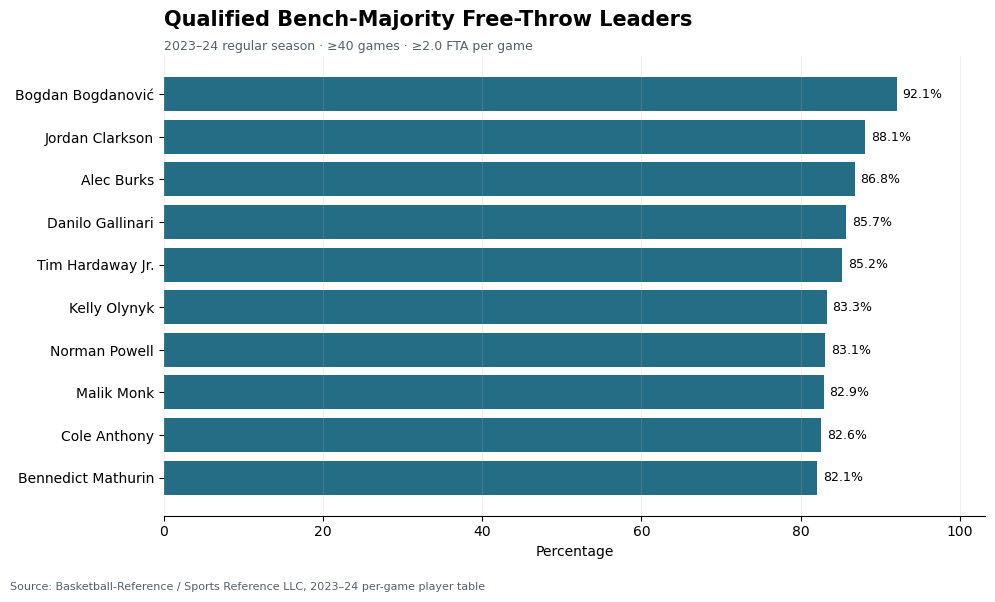

In [7]:
fig = plot_leaderboard(
    boards['free_throw'], value_column='FT%',
    title='Qualified Bench-Majority Free-Throw Leaders',
    subtitle='2023–24 regular season · ≥40 games · ≥2.0 FTA per game',
    output_path=figure_dir / 'free_throw_leaders.png', percentage=True,
)
plt.show()

## Rebounding — qualified cohort

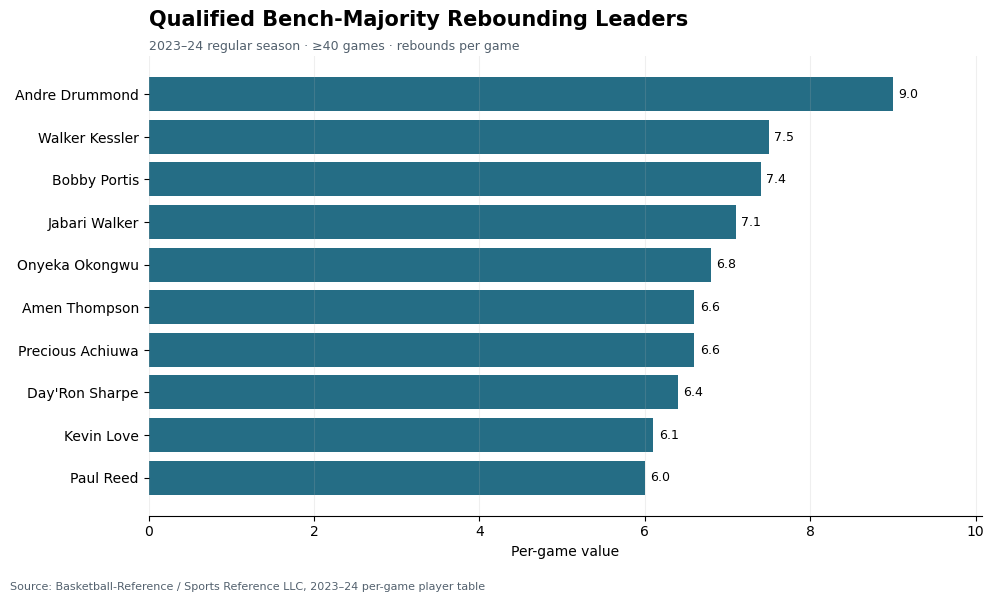

In [8]:
fig = plot_leaderboard(
    boards['rebounding'], value_column='TRB',
    title='Qualified Bench-Majority Rebounding Leaders',
    subtitle='2023–24 regular season · ≥40 games · rebounds per game',
    output_path=figure_dir / 'rebounding_leaders.png', percentage=False,
)
plt.show()

## Findings

- Norman Powell leads the qualified three-point group at **43.5%** on 5.1 attempts per game.
- Walker Kessler leads the qualified two-point group at **68.0%** on 5.2 attempts per game.
- Bogdan Bogdanović leads the qualified free-throw group at **92.1%** on 2.1 attempts per game.
- Andre Drummond leads the cohort with **9.0 rebounds per game**.

These are descriptive findings for the stated cohort and thresholds, not causal claims or current-player evaluations.

## Limitations and next steps

- Per-game statistics omit lineup context, defense, role difficulty, and playoff performance.
- The bench-majority definition and sample thresholds are analytical choices.
- A future version could compare rate statistics, minutes-normalized production, and sensitivity to thresholds.